## What is Random Forest?

Random Forest is an ensemble learning algorithm that combines multiple Decision Trees to make a prediction.

Instead of depending on one Decision Tree, it trains many trees and combines their predictions.

For classification, it uses majority voting.

### Why Random Forest?
A single Decision Tree can easily overfit. Random Forest reduces this risk by combining multiple trees trained on different samples and feature subsets.

Important concepts:
- Bootstrap Sampling: Each tree trains on a randomly sampled dataset, with replacement.
- Random Feature Selection: Each split considers a random subset of features.
- Majority Voting: The class receiving the most votes becomes the final prediction.
- Ensemble Learning: Combining multiple models to improve predictions.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

In [2]:
data = load_breast_cancer(as_frame=True)

df = data.frame

X = df.drop(columns="target")
y = df["target"]

print("Dataset shape:", df.shape)
print("Features:", X.shape)
print("Target:", y.shape)

Dataset shape: (569, 31)
Features: (569, 30)
Target: (569,)


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [4]:
model = RandomForestClassifier(
    n_estimators=100,
    criterion="gini",
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features="sqrt",
    random_state=42,
    n_jobs=-1
)

model.fit(X_train,y_train)

,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total

In [5]:
y_pred = model.predict(X_test)

print("Predictions:", y_pred[:10])
print("Actual:", y_test.iloc[:10].values)

Predictions: [0 1 0 0 0 1 1 0 0 0]
Actual: [0 1 0 1 0 1 1 0 0 0]


In [6]:
print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=data.target_names
))

Accuracy: 0.956140350877193

Confusion Matrix:
[[39  3]
 [ 2 70]]

Classification Report:
              precision    recall  f1-score   support

   malignant       0.95      0.93      0.94        42
      benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



In [7]:
y_prob = model.predict_proba(X_test)

probability_df = pd.DataFrame(
    y_prob[:10],
    columns=data.target_names
)

print(probability_df)

   malignant  benign
0       1.00    0.00
1       0.00    1.00
2       0.88    0.12
3       0.72    0.28
4       0.99    0.01
5       0.01    0.99
6       0.05    0.95
7       0.99    0.01
8       1.00    0.00
9       1.00    0.00


In [8]:
importance = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print(importance.head(10))

worst area              0.140016
worst concave points    0.129530
worst radius            0.097696
mean concave points     0.090885
worst perimeter         0.072226
mean perimeter          0.069574
mean radius             0.068676
mean concavity          0.057638
mean area               0.049172
worst concavity         0.034340
dtype: float64


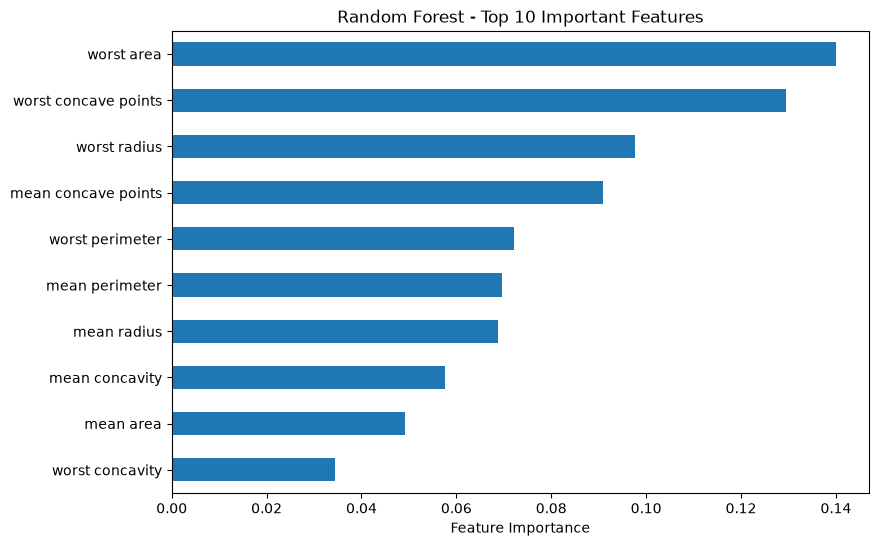

In [9]:
importance.head(10).sort_values().plot(
    kind="barh",
    figsize=(9, 6)
)

plt.title("Random Forest - Top 10 Important Features")
plt.xlabel("Feature Importance")
plt.show()

In [10]:
tree_counts = [10, 50, 100, 200, 300]

results = []

for n in tree_counts:

    rf = RandomForestClassifier(
        n_estimators=n,
        random_state=42,
        n_jobs=-1
    )

    rf.fit(X_train, y_train)

    train_accuracy = rf.score(X_train, y_train)
    test_accuracy = rf.score(X_test, y_test)

    results.append({
        "Trees": n,
        "Train Accuracy": train_accuracy,
        "Test Accuracy": test_accuracy
    })

results_df = pd.DataFrame(results)

print(results_df)

   Trees  Train Accuracy  Test Accuracy
0     10        0.995604       0.938596
1     50        1.000000       0.956140
2    100        1.000000       0.956140
3    200        1.000000       0.956140
4    300        1.000000       0.947368


In [11]:
scores = cross_val_score(
    RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=1
    ),
    X_train,
    y_train,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

print("CV Scores:", scores)
print("Mean CV Accuracy:", scores.mean())

CV Scores: [0.96703297 0.98901099 0.92307692 0.93406593 0.95604396]
Mean CV Accuracy: 0.953846153846154


In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000))
    ]),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=4,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )
}

comparison = []

for name, estimator in models.items():

    estimator.fit(X_train, y_train)

    train_acc = estimator.score(X_train, y_train)
    test_acc = estimator.score(X_test, y_test)

    comparison.append({
        "Model": name,
        "Train Accuracy": train_acc,
        "Test Accuracy": test_acc
    })

comparison_df = pd.DataFrame(comparison)

print(comparison_df)

                 Model  Train Accuracy  Test Accuracy
0  Logistic Regression        0.989011       0.982456
1        Decision Tree        0.986813       0.938596
2        Random Forest        1.000000       0.956140
